# Credit Card Default Risk Analysis

## 1. Business Problem

Credit card companies face financial losses when customers fail to repay their outstanding credit card bills. Delayed payments, high outstanding balances and poor repayment behaviour can increase the risk of customer defaults.

Banks need to understand which customer behaviours and financial factors are associated with payment defaults so they can improve their credit risk management and collection strategies.

## 2. Project Objective

The objective of this project is to analyse customer repayment behaviour and identify patterns associated with credit card payment defaults.

The analysis will focus on:

- Understanding customer repayment and spending behaviour.
- Analysing payment delays and outstanding balances.
- Examining credit utilisation and its relationship with payment defaults.
- Applying relevant statistical hypothesis tests to identify significant differences and relationships.
- Deriving actionable business insights to support better credit risk management.

## 3. Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SciPy

## 1. Dataset Loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [21]:
import pandas as pd

df = pd.read_excel('/content/default of credit card clients.xls')

df.to_csv('credit_card_data.csv', index=False)

In [59]:
df = pd.read_csv("credit_card_data.csv")

## 2. Dataset Overview

In [61]:
# Restore actual column names
df.columns = df.iloc[0]

# Remove the first row containing column names
df = df.iloc[1:].reset_index(drop=True)

# Remove ID column
df = df.drop(columns=['ID'])

# Convert columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

In [25]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
print(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (30001, 25)

First 5 Rows:


,Unnamed: 0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X15,X16,X17,X18,X19,X20,X21,X22,X23,Y
0,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
1,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
2,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
3,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
4,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0



Column Names:
['Unnamed: 0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'X19', 'X20', 'X21', 'X22', 'X23', 'Y']


In [27]:
print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes.value_counts())

print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (30000, 24)

Data Types:
int64    24
Name: count, dtype: int64

Column Names:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


### Dataset Overview – Observations

- The dataset contains 30,000 customer records and 24 columns.
- The unnecessary Customer ID column has been removed.
- All 24 columns are currently stored as integer data types.
- The dataset includes customer demographics, credit limits, repayment history, bill amounts, payment amounts and next-month default status.

The dataset is now ready for data quality checks and further analysis.

## 3. Data Quality Checks

In [31]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

Missing Values:
0

Duplicate Records:
35


### Data Quality Check – Observations

- No missing values were found in the dataset.
- 35 potential duplicate records were identified after excluding the Customer ID column.
- These records require further investigation before deciding whether they should be removed.

In [32]:
# Remove duplicate records
df.drop_duplicates(inplace=True)

print("Dataset Shape after removing duplicates:", df.shape)

Dataset Shape after removing duplicates: (29965, 24)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Default vs Non-Default Customer Distribution

The first step is to examine the distribution of customers who defaulted on their credit card payments and those who did not.

This analysis will help us understand the proportion of defaulting customers in the dataset and identify whether the target classes are balanced or imbalanced.

Customer Default Distribution:
default payment next month
0    23335
1     6630
Name: count, dtype: int64

Percentage Distribution:
default payment next month
0    77.87
1    22.13
Name: count, dtype: float64


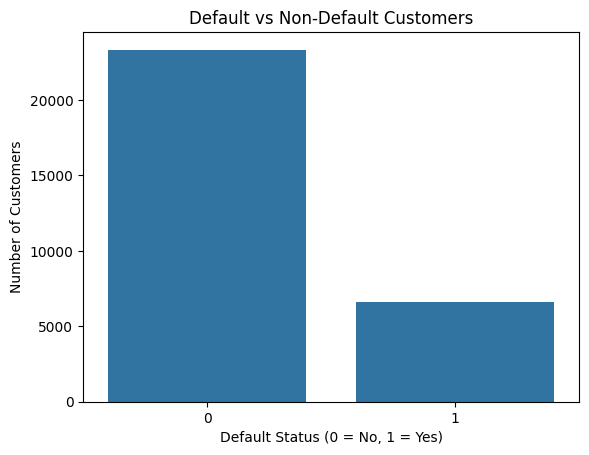

In [33]:
# Count default and non-default customers
default_counts = df['default payment next month'].value_counts().sort_index()

print("Customer Default Distribution:")
print(default_counts)

# Calculate percentages
print("\nPercentage Distribution:")
print((default_counts / len(df) * 100).round(2))

# Visualize distribution
sns.countplot(data=df, x='default payment next month')
plt.title('Default vs Non-Default Customers')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()

### Key Observations

- 77.87% of customers did not default on their next month's payment.
- 22.13% of customers defaulted on their next month's payment.
- The dataset contains a higher proportion of non-default customers.
- Further analysis is required to understand which repayment patterns are associated with customer defaults.

### 4.2 Repayment Delay Analysis

This analysis examines customers' previous repayment status to understand their payment patterns and identify the frequency of payment delays.


PAY_0
-2     2750
-1     5682
 0    14737
 1     3667
 2     2666
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64


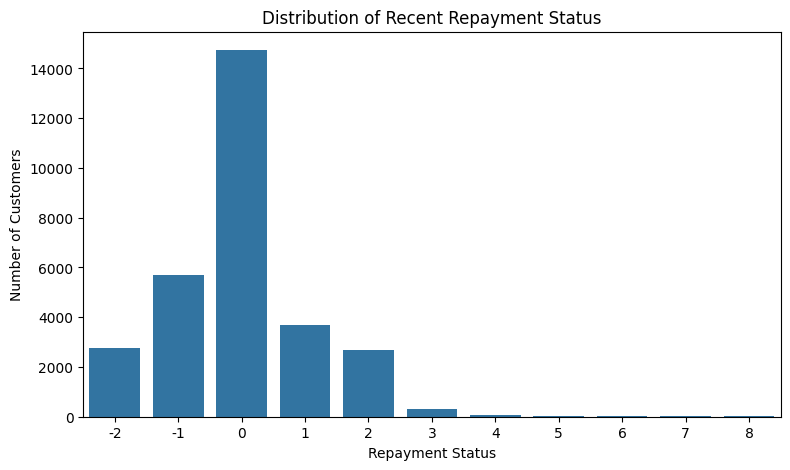

In [34]:
# Analyse recent repayment status
print(df['PAY_0'].value_counts().sort_index())

# Visualize repayment status
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x='PAY_0', order=sorted(df['PAY_0'].unique()))

plt.title('Distribution of Recent Repayment Status')
plt.xlabel('Repayment Status')
plt.ylabel('Number of Customers')
plt.show()

### Key Observations

- The majority of customers fall under repayment status category 0.
- 5,682 customers paid their dues on time.
- 3,667 customers experienced a one-month payment delay.
- A smaller group of customers experienced longer payment delays.
- Previous repayment behaviour requires further investigation to understand its relationship with future payment defaults.

### 4.3 Repayment Status vs Next-Month Defaul

In [35]:
# Calculate default rate for each repayment status
repayment_analysis = df.groupby('PAY_0')['default payment next month'].agg(
    ['count', 'mean']
)

repayment_analysis['default_rate'] = repayment_analysis['mean'] * 100

repayment_analysis = repayment_analysis.drop(columns='mean')

print(repayment_analysis.round(2))

       count  default_rate
PAY_0                     
-2      2750         13.24
-1      5682         16.79
 0     14737         12.81
 1      3667         34.03
 2      2666         69.13
 3       322         75.78
 4        76         68.42
 5        26         50.00
 6        11         54.55
 7         9         77.78
 8        19         57.89


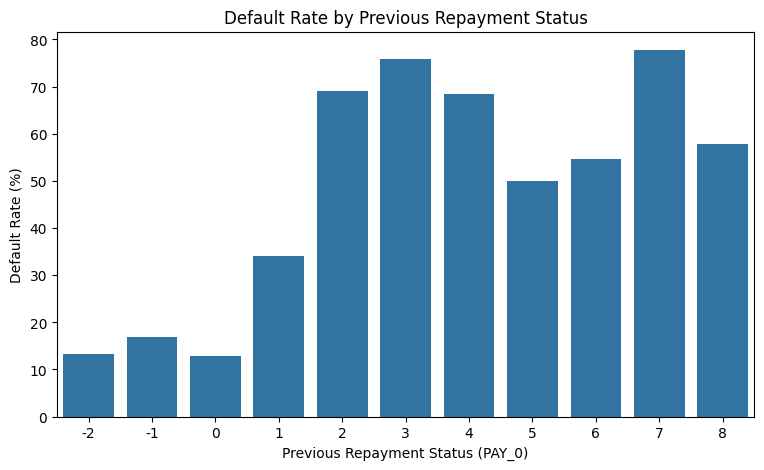

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=repayment_analysis.index,
    y=repayment_analysis['default_rate']
)

plt.title('Default Rate by Previous Repayment Status')
plt.xlabel('Previous Repayment Status (PAY_0)')
plt.ylabel('Default Rate (%)')
plt.show()

### Key Observations

- Customers with no recent payment delay generally show lower default rates.
- Customers with a one-month payment delay have a default rate of 34.03%.
- Customers with a two-month payment delay have a significantly higher default rate of 69.13%.
- Customers with a three-month payment delay show a default rate of 75.78%.
- Overall, longer payment delays appear to be associated with higher default rates.

**Business Insight:** Previous payment delays may serve as an important warning indicator for identifying customers who are more likely to default on their next payment.

### 4.4 Credit Limit vs Default

This analysis examines the relationship between customers assigned credit limits and their next-month default status.

The objective is to understand whether customers with different credit limits show different default patterns.

In [38]:
# Compare average credit limit by default status

credit_analysis = df.groupby('default payment next month')['LIMIT_BAL'].agg(
    ['mean', 'median', 'count']
)

print(credit_analysis.round(2))

                                 mean    median  count
default payment next month                            
0                           178084.51  150000.0  23335
1                           129984.57   90000.0   6630


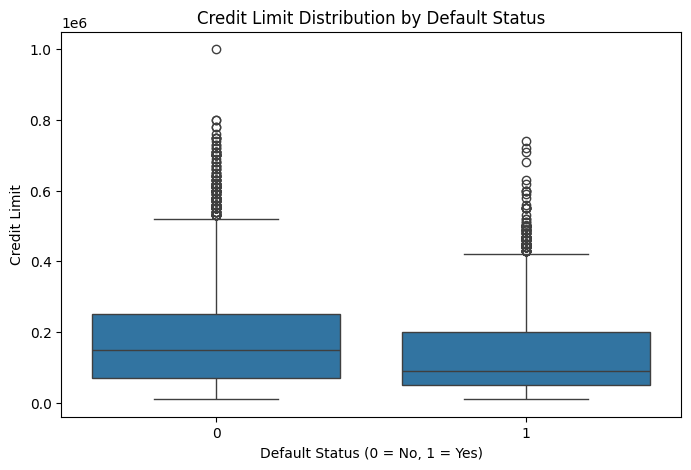

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='default payment next month',
    y='LIMIT_BAL'
)

plt.title('Credit Limit Distribution by Default Status')
plt.xlabel('Default Status (0 = No, 1 = Yes)')
plt.ylabel('Credit Limit')
plt.show()

### Key Observations

- Customers who did not default had a higher average credit limit (178,084.51) compared to defaulting customers (129,984.57).
- The median credit limit was also higher for non-default customers (150,000) than default customers (90,000).
- The analysis indicates an association between credit limit and default behaviour.
- Further statistical testing is required to determine whether this difference is statistically significant.

### 4.5 Bill Amount vs Default

This analysis compares the outstanding credit card bill amounts of defaulting and non-defaulting customers to understand whether their billing patterns differ.

In [40]:
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
             'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']

bill_analysis = df.groupby('default payment next month')[bill_cols].mean()

print(bill_analysis.round(2))

0                           BILL_AMT1  BILL_AMT2  BILL_AMT3  BILL_AMT4  \
default payment next month                                               
0                            52058.72   49779.10   47592.31   43665.24   
1                            48552.81   47326.16   45222.24   42074.74   

0                           BILL_AMT5  BILL_AMT6  
default payment next month                        
0                            40580.69   39090.67  
1                            39575.72   38305.82  


### Key Observations

- Non-default customers had higher average outstanding bill amounts across all six months.
- Default customers showed comparatively lower average bill amounts.
- Outstanding bill amount alone does not clearly distinguish defaulting customers from non-defaulting customers.
- Further analysis of repayment amounts and payment behaviour is required.

### 4.6 Payment Amount vs Default

This analysis compares the payment amounts of defaulting and non-defaulting customers over the six-month period to understand differences in their repayment patterns.

In [41]:
pay_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
            'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

payment_analysis = df.groupby('default payment next month')[pay_cols].mean()

print(payment_analysis.round(2))

0                           PAY_AMT1  PAY_AMT2  PAY_AMT3  PAY_AMT4  PAY_AMT5  \
default payment next month                                                     
0                            6315.05   6648.59   5760.52   5306.99   5254.62   
1                            3400.12   3391.72   3370.40   3158.48   3222.05   

0                           PAY_AMT6  
default payment next month            
0                            5726.36  
1                            3444.60  


### Key Observations

- Non-default customers consistently showed higher average payment amounts across all six months.
- Defaulting customers had comparatively lower average repayment amounts.
- Differences in repayment amounts indicate a potential relationship between customer payment behaviour and default status.
- Further statistical testing is required to determine whether these differences are statistically significant.

## 5. Feature Engineering

Feature engineering involves creating meaningful variables from existing data to gain better insights into customer behaviour.

we will create relevant features to understand customers credit utilisation and repayment patterns.

## 5.1 Credit Utilization

In [42]:
# Calculate average bill amount over 6 months
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3',
             'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']

df['AVG_BILL_AMT'] = df[bill_cols].mean(axis=1)

# Calculate credit utilization
df['CREDIT_UTILIZATION'] = (
    df['AVG_BILL_AMT'] / df['LIMIT_BAL']
) * 100

df[['LIMIT_BAL', 'AVG_BILL_AMT', 'CREDIT_UTILIZATION']].head()

,LIMIT_BAL,AVG_BILL_AMT,CREDIT_UTILIZATION
0,20000,1284.000000,6.420000
1,120000,2846.166667,2.371806
2,90000,16942.166667,18.824630
3,50000,38555.666667,77.111333
4,50000,18223.166667,36.446333


## 5.2 Average Payment Amount

In [43]:
pay_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3',
            'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']

df['AVG_PAYMENT_AMT'] = df[pay_cols].mean(axis=1)

df[['AVG_PAYMENT_AMT']].head()

,AVG_PAYMENT_AMT
0,114.833333
1,833.333333
2,1836.333333
3,1398.000000
4,9841.500000


## 5.3 Feature Verification

In [47]:
df[['AVG_BILL_AMT', 'CREDIT_UTILIZATION',
    'AVG_PAYMENT_AMT']].describe()

,AVG_BILL_AMT,CREDIT_UTILIZATION,AVG_PAYMENT_AMT
count,29965.000000,29965.000000,29965.000000
mean,45029.328116,37.348044,5281.297308
std,63279.074163,35.186732,10142.306855
min,-56043.166667,-23.259000,0.000000
25%,4841.000000,3.030000,1116.666667
50%,21110.833333,28.562889,2400.000000
75%,57166.166667,68.845417,5600.000000
max,877313.833333,536.430833,627344.333333


### Feature Engineering – Observations

- Average bill amount and average payment amount were calculated using six months of historical data.
- Credit utilization was derived using average bill amount and credit limit.
- The dataset contains some negative bill amounts and unusually high credit utilization values.
- These observations will be considered while interpreting statistical results.

## 6. Hypothesis Testing

### 6.1 Credit Utilization vs Default Risk

**Business Question:** Is there a statistically significant difference in average credit utilization between customers who defaulted and those who did not?

**Null Hypothesis (H₀):** There is no significant difference in average credit utilization between default and non-default customers.

**Alternative Hypothesis (H₁):** There is a significant difference in average credit utilization between default and non-default customers.

**Statistical Test:** T-test.

**Significance Level (α):** 0.05

**Reason for Test Selection:** Credit utilization is a numerical variable, while default status divides customers into two independent groups. T-test compares the mean of two independent groups and does not assume equal variances.

In [52]:
default_group = df[df['default payment next month'] == 1]['CREDIT_UTILIZATION']

non_default_group = df[df['default payment next month'] == 0]['CREDIT_UTILIZATION']

print("Default Group Mean:", default_group.mean())
print("Non-Default Group Mean:", non_default_group.mean())

print("Default Group Size:", len(default_group))
print("Non-Default Group Size:", len(non_default_group))

Default Group Mean: 44.969169874674535
Non-Default Group Mean: 35.18271065522059
Default Group Size: 6630
Non-Default Group Size: 23335


In [53]:
t_stat, p_value = stats.ttest_ind(
    default_group,
    non_default_group,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-value:", p_value)

T-Statistic: 19.334651790427337
P-value: 8.11871461154867e-82


**Findings:**

- The average credit utilization of default customers was 44.97%, compared to 35.18% for non-default customers.
- T-test returned a T-statistic of 19.33 and a p-value of approximately 8.11 × 10⁻⁸².
- Since the p-value is below the 0.05 significance level, the null hypothesis was rejected.
- The results indicate a statistically significant difference in average credit utilization between the two groups.

**Business Interpretation:**

Customers who defaulted had significantly higher average credit utilization than customers who did not default. This suggests that higher credit utilization is associated with greater default risk and may be useful for customer risk monitoring.

### 6.2 Average Payment Amount vs Default Risk

**Business Question:** Is there a statistically significant difference in the average payment amount between customers who defaulted and those who did not?

**Null Hypothesis (H₀):** There is no significant difference in the average payment amount between default and non-default customers.

**Alternative Hypothesis (H₁):** There is a significant difference in the average payment amount between default and non-default customers.

**Statistical Test:** T-test.

**Significance Level (α):** 0.05

**Reason for Test Selection:** Average payment amount is a numerical variable, while default status divides customers into two independent groups. T-test is suitable for comparing their average payment amounts without assuming equal variances.

In [54]:
default_payment = df[df['default payment next month'] == 1]['AVG_PAYMENT_AMT']

non_default_payment = df[df['default payment next month'] == 0]['AVG_PAYMENT_AMT']

print("Default Group Mean:", default_payment.mean())
print("Non-Default Group Mean:", non_default_payment.mean())

print("Default Group Size:", len(default_payment))
print("Non-Default Group Size:", len(non_default_payment))

Default Group Mean: 3331.227576671695
Non-Default Group Mean: 5835.356117420184
Default Group Size: 6630
Non-Default Group Size: 23335


In [55]:
t_stat, p_value = stats.ttest_ind(
    default_payment,
    non_default_payment,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-value:", p_value)

T-Statistic: -24.036632138520858
P-value: 7.852319038222781e-126


**Findings:**

- The average payment amount of default customers was 3,331.23, compared to 5,835.36 for non-default customers.
- T-test returned a T-statistic of -24.04 and a p-value of approximately 7.85 × 10⁻¹²⁶.
- Since the p-value is below the 0.05 significance level, the null hypothesis was rejected.
- The results indicate a statistically significant difference in average payment amounts between default and non-default customers.

**Business Interpretation:**

Customers who defaulted had lower average payment amounts than non-default customers. This suggests that lower repayment amounts are associated with higher default risk. Banks may use repayment behaviour as one factor when identifying customers who require closer monitoring.

### 6.3 Credit Limit vs Default Risk

**Business Question:** Is there a statistically significant difference in the average credit limit between customers who defaulted and those who did not?

**Null Hypothesis (H₀):** There is no significant difference in the average credit limit between default and non-default customers.

**Alternative Hypothesis (H₁):** There is a significant difference in the average credit limit between default and non-default customers.

**Statistical Test:** Welch's Independent T-test.

**Significance Level (α):** 0.05

**Reason for Test Selection:** Credit limit is a numerical variable, while default status divides customers into two independent groups. Welch's T-test is suitable for comparing their average credit limits without assuming equal variances.

In [56]:
default_limit = df[df['default payment next month'] == 1]['LIMIT_BAL']

non_default_limit = df[df['default payment next month'] == 0]['LIMIT_BAL']

print("Default Group Mean:", default_limit.mean())
print("Non-Default Group Mean:", non_default_limit.mean())

print("Default Group Size:", len(default_limit))
print("Non-Default Group Size:", len(non_default_limit))

Default Group Mean: 129984.56711915536
Non-Default Group Mean: 178084.50824941075
Default Group Size: 6630
Non-Default Group Size: 23335


In [57]:
t_stat, p_value = stats.ttest_ind(
    default_limit,
    non_default_limit,
    equal_var=False
)

print("T-Statistic:", t_stat)
print("P-value:", p_value)

T-Statistic: -29.023212521937214
P-value: 4.791668336557928e-179


**Findings:**

- The average credit limit of default customers was 129,984.57, compared to 178,084.51 for non-default customers.
- Welch's Independent T-test returned a T-statistic of -29.02 and a p-value of approximately 4.79 × 10⁻¹⁷⁹.
- Since the p-value is below the 0.05 significance level, the null hypothesis was rejected.
- The results indicate a statistically significant difference in average credit limits between default and non-default customers.

**Business Interpretation:**

Customers who defaulted had significantly lower average credit limits than non-default customers. This indicates an association between credit limit and default behaviour. However, credit limit alone cannot explain or establish the cause of default.

## 7. Overall Conclusion

The analysis of credit card default behaviour revealed several important patterns:

1. **Repayment Behaviour:** Customers with longer previous payment delays generally showed higher next-month default rates.

2. **Credit Utilization:** Default customers had a higher average credit utilization (44.97%) compared to non-default customers (35.18%).

3. **Payment Amount:** Default customers had a lower average payment amount (3,331.23) compared to non-default customers (5,835.36).

4. **Credit Limit:** Default customers had a lower average credit limit (129,984.57) compared to non-default customers (178,084.51).

The hypothesis testing results showed statistically significant differences in average credit utilization, payment amount and credit limit between default and non-default customers.

Overall, repayment behaviour and financial characteristics were significantly associated with credit card default status in the analysed dataset.

## 8. Business Recommendations

Based on the analysis, the following recommendations can support credit risk management:

1. **Monitor Payment Delays:** Identify customers with repeated payment delays and initiate timely follow-ups.

2. **Track High Credit Utilization:** Monitor customers using a high proportion of their available credit limit.

3. **Monitor Repayment Behaviour:** Identify customers making relatively low payments and assess their repayment patterns.

4. **Review Customer Risk Profiles:** Consider credit limits and repayment behaviour together rather than relying on a single financial factor.

5. **Proactive Risk Management:** Use these insights to support early identification and monitoring of customers who may require additional attention.

These recommendations should be used as supporting indicators rather than standalone decisions for assessing customer default risk.

## 9. Project Limitations

- The analysis uses a historical dataset from Taiwan (2005), so the findings may not represent current credit card customer behaviour.
- The analysis identifies statistical associations and differences but does not establish causal relationships.
- Extreme values and skewed financial variables may influence average-based comparisons.
- The project focuses on statistical analysis and does not build a predictive machine learning model.